### 리트리버

In [1]:
from glob import glob 

for g in glob('data/*.pdf'):
    print(g)

data\2040_seoul_plan.pdf
data\OneNYC_2050_Strategic_Plan.pdf


In [2]:
import pymupdf
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter


def read_pdf_and_split_text(pdf_path, chunk_size=1000, chunk_overlap=100):
    print(f"PDF: {pdf_path} -----------------------------")

    with pymupdf.open(pdf_path) as pdf:
        data_from_pdf = [
            Document(
                page_content=page.get_text(),
                metadata={"source": str(pdf_path), "page": i},
            )
            for i, page in enumerate(pdf)
        ]

    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
    )
    splits = text_splitter.split_documents(data_from_pdf)

    print(f"Number of splits: {len(splits)}\n")
    return splits

In [3]:
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
import os

##### Vectorstore 설정 #####
embedding = OpenAIEmbeddings(model='text-embedding-3-large')

persist_directory='chroma_store'

if os.path.exists(persist_directory):
    print("Loading existing Chroma store")
    vectorstore = Chroma(
        persist_directory=persist_directory, 
        embedding_function=embedding
    )
else:
    print("Creating new Chroma store")
    
    vectorstore = None
    for g in glob('data/*.pdf'):
        chunks = read_pdf_and_split_text(g)
        # 100개씩 나눠서 저장
        for i in range(0, len(chunks), 100):
            if vectorstore is None:
                vectorstore = Chroma.from_documents(
                    documents=chunks[i:i+100],
                    embedding=embedding,
                    persist_directory=persist_directory
                )
            else:
                vectorstore.add_documents(
                    documents=chunks[i:i+100]
                )

Creating new Chroma store
PDF: data\2040_seoul_plan.pdf -----------------------------
Number of splits: 289

PDF: data\OneNYC_2050_Strategic_Plan.pdf -----------------------------
Number of splits: 1016



In [4]:
retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

chunks = retriever.invoke("서울 온실가스 저감 계획")

for chunk in chunks:
    print(chunk.metadata)
    print(chunk.page_content)

{'page': 63, 'source': 'data\\2040_seoul_plan.pdf'}
56
제2장 미래상과 목표
6. 미래위기를 준비하는, ‘탄소중립 안전도시 구축’
1) 배경
전(全) 지구적인 기후변화에 대응하기 위한 대도시 차원의 대응 필요
Ÿ 서울시 2017년 온실가스 배출량은 46,685천 톤CO2eq로 2005년 배출량에 비해 5.6%(276만 톤
CO2eq) 감소하였으며, 서울의 1인당 온실가스 배출량은 4.7CO2eq로 국가의 13.8톤CO2eq에 비
해 낮은 수준이다. 또한 2014년 기준 서울의 1인당 온실가스 배출량은 4.5CO2eq로 세계 주요 도시
에 비해 낮은 수준을 보인다.7)
[그림 2-26] 세계 주요 도시 1인당 온실가스 배출량
   자료: World Bank, 2014
Ÿ 그럼에도 불구하고, 기후변화 문제는 21세기에 전 지구적으로 가장 위중한 영향을 미칠 것으로 예
상되는바, 탄소중립과 기후위기 대응은 국제·국가·도시의 핵심 정책으로 다루어져야 한다.
Ÿ 파리협정(2015) 이후, 우리나라를 비롯한 미국, 유럽연합 등 세계 136개국이 탄소중립을 선언하였
으며, 서울시를 비롯한 뉴욕, 런던 등과 같은 많은 글로벌 도시에서 탄소중립을 시정의 핵심과제로 
추진 중이다.
Ÿ 우리나라는 2020년 ‘한국판 그린뉴딜’을 발표하며 공식적으로 2050 탄소중립을 선언하였으며 
서울시 역시 2020년 ‘그린뉴딜 추진을 통한 2050 온실가스 감축 전략’을 발표하고 탄소중립 선언에 
따른 부문별 사업을 적극 추진하고 있다.
- 서울시는 2050년 탄소중립을 목표로 2030년까지 2005년 배출량 대비 40%, 2040년까지 70% 감축
목표를 제시하였고, 2022년 기후변화대응종합계획을 수립하여, 향후 5년간(’22~’26년) 2005년 대비 
온실가스 30% 감축목표와 구체적인 실행계획을 수립하였음
7) 황인창 외, 2020, 파리협정 이행 위한 서울시 ‘2050 탄소중립’ 전략, 서울연구원, pp.6-9.
{'page': 45, '

In [30]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(
    model="gpt-5.6-luna",
    reasoning_effort="none",
)
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 14, 'prompt_tokens': 9, 'total_tokens': 23, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EaJUstnGYocEi454IZFPZLBlFyVVC', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14ecd-a145-7142-84bb-e88fa88d51d0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 14, 'total_tokens': 23, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

### 라우터
- 사용자의 질문에 따라 RAG의 사용 여부를 판단해야 함
- 이런 판단을 처리하려면 라우터 기능이 필요함.
- 입력 내용에 따라 여러 개의 실행 경로 중 적절한 경로를 결정해 다음 노드를 선택하는 기능을 함.
- 언어 모델의 응답이나 특정 조건에 따라 다르게 동작해야 할 때 라우터를 사용 함.

In [31]:
# Router 설정
from langchain_core.prompts import ChatPromptTemplate
from typing import Literal # 문자열 리터럴 타입을 지원하는 typing 모듈의 클래스
from pydantic import BaseModel, Field

# Data model
class RouteQuery(BaseModel):
    """사용자 쿼리를 가장 관련성이 높은 데이터 소스로 라우팅합니다."""
    
    datasource: Literal["vectorstore", "casual_talk"] = Field(
        ...,
        description="""
        사용자 질문에 따라 casual_talk 또는 vectorstore로 라우팅합니다.
        - casual_talk: 일상 대화를 위한 데이터 소스. 사용자가 일상적인 질문을 할 때 사용합니다.
        - vectorstore: 사용자 질문에 답하기 위해 RAG로 vectorstore 검색이 필요한 경우 사용합니다.
        """,
    )

In [32]:
# 특정 모델을 structured output (구조화된 출력)과 함께 사용하기 위해 설정
structured_llm_router = model.with_structured_output(
    RouteQuery,
    method="function_calling",
)

router_system = """
당신은 사용자의 질문을 vectorstore 또는 casual_talk으로 라우팅하는 전문가입니다.
- vectorstore에는 서울, 뉴욕의 발전계획과 관련된 문서가 포함되어 있습니다. 이 주제에 대한 질문에는 vectorstore를 사용하십시오.
- 사용자의 질문이 일상 대화에 관련된 경우 casual_talk을 사용하십시오.
"""

# 시스템 메시지와 사용자의 질문을 포함하는 프롬프트 템플릿 생성
route_prompt = ChatPromptTemplate.from_messages([
    ("system", router_system),
    ("human", "{question}"),
])

# 라우터 프롬프트와 구조화된 출력 모델을 결합한 객체
question_router = route_prompt | structured_llm_router

In [33]:
print(
    question_router.invoke({
        "question": "서울 온실가스 저감 계획은 무엇인가요?"
    })
)

print(question_router.invoke({"question": "잘 지냈어?"}))

datasource='vectorstore'
datasource='casual_talk'


### 관련 있는 청크만 필터링하기
- 리트리버는 벡터 DB에서 벡터 유사도를 기준으로 가장 관련 있는 문서 n개 가져옴.
- n개를 가져오기 때문에 그 중에서 관련 없는 청크가 선택될 수도 있음
- 질문과 관련 없는 청크를 포함 하는 경우 미리 삭제하는 것이 목표

In [34]:
from langchain_core.prompts import PromptTemplate

class GradeDocuments(BaseModel):
    """검색된 문서가 질문과 관련성 있는지 yes 또는 no로 평가합니다."""

    binary_score: Literal["yes", "no"] = Field(
        description="문서가 질문과 관련이 있는지 여부를 'yes' 또는 'no'로 평가합니다."
    )

structured_llm_grader = model.with_structured_output(
    GradeDocuments,
    method="function_calling",
)

In [35]:
grader_prompt = PromptTemplate.from_template("""
당신은 검색된 문서가 사용자 질문과 관련이 있는지 평가하는 평가자입니다. \n 
문서에 사용자 질문과 관련된 키워드 또는 의미가 포함되어 있으면, 해당 문서를 관련성이 있다고 평가하십시오. \n
엄격한 테스트가 필요하지 않습니다. 목표는 잘못된 검색 결과를 걸러내는 것입니다. \n
문서가 질문과 관련이 있는지 여부를 나타내기 위해 'yes' 또는 'no'로 이진 점수를 부여하십시오.
                                             
Retrieved document: \n {document} \n\n 
User question: {question}
""")

retrieval_grader = grader_prompt | structured_llm_grader
question = "서울시 자율주행 관련 계획"
documents = retriever.invoke(question)

for doc in documents:
    print(doc)

page_content='54
제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’
1) 배경
미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비
Ÿ 빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 
변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 
교통체계 구축을 준비해야 한다.
미래교통수단 정착을 위한 도시 인프라 확충지원 필요
Ÿ 기존에 없던 새로운 교통은 통상 인프라 구축에 많은 시간이 소요되기 때문에 교통수단이 도입된 이
후에 준비하기보다는 개발단계에서부터 이를 지원하기 위한 교통인프라 구축 구상이 요구되며, 새
로운 도시 인프라 확충에 대한 도시계획적 지원이 필요하다.
2) 추진전략
자율주행 자동차 본격 운영 체계 구축
Ÿ 자율주행은 현재 제일 가시화되고 있는 미래 교통기술로 시장의 주도권을 확보하기 위해 각국의 
노력이 집중되고 있다. 단계적으로 2030년까지 간선도로급 이상 도로에서 운영할 수 있는 도로 
인프라 환경을 조성하고, 2040년까지 서울 전역 자율주행 운행 환경 구축을 목표로 한다.
- 2040년까지 서울 전역 자율주행차량의 운행 환경을 구축하고 수송 분담률 10%를 달성
서울형 도심 항공교통 기반 마련 및 터미널 확충
Ÿ 도심에서 김포공항까지 시범노선을 운영하는 등 상용화 노선을 확보하고, 장기적으로 한강, 지천 등 
주요 수변 공간 중심으로 광역노선을 확보한다. 또한 UAM 인프라 확보를 위한 인센티브 및 도시계
획적인 지원 방안도 함께 검토한다.
- UAM 시범노선을 운영하고, 한강 등 주요 수변 공간 중심에 단계적 광역노선을 확장
서울 전역에 모빌리티 허브 구축
Ÿ 도심 및 광역거점에 서울 내부와 외부의 연계를 위한 미래 교통과 기존 교통을 연결하는 시설을 도
입한다. 또한 교통뿐 아니라 공공서비스, 물류, 상업 등 다양한 기능들이 복합적으로 제공되는 지
역 거점 모빌리티 허브를 서울 전역에 도

- 가져온 청크 중 '서울시 자율주행 계획'과 관련된 문서만 찾아서 filtered_docs에 담음
- 각 청크는 retrieval_grader로 연관성을 판단하여 결과를 받아 is_relevant에 담음
- 결과가 yes인 경우에만 해당 청크가 filtered_docs 리스트에 추가됨

In [36]:
filtered_docs = []

for i, doc in enumerate(documents):
    print(f"Document {i + 1}:")
    is_relevant = retrieval_grader.invoke({"question": question, "document": doc.page_content})
    print(is_relevant)
    print(doc.page_content[:200])
    print("=================================\n\n")

    if is_relevant.binary_score == "yes":
        filtered_docs.append(doc)

print(f"Filtered documents: {len(filtered_docs)}")

Document 1:
binary_score='yes'
54
제2장 미래상과 목표
5. 기술발전에 선제적 대응, ‘미래교통 인프라 구축’
1) 배경
미래교통수단 도입에 따른 도시 활동 변화 및 공간구조 재편 대비
Ÿ 빠르게 진화하는 미래 신 교통수단은 도시공간에 새로운 변화를 일으킬 것이며, 도시 내 이동패턴의 
변화를 가져올 것으로 예측된다. 이러한 점을 고려하여 도시 내 다양한 통행행태가 공존하는 포용적인 


Document 2:
binary_score='yes'
확충한다.
- 자율주행 자동차 기반 구축, 서울형 도심항공 교통인프라 확보, 모빌리티 허브 및 3차원 물류체계 
구축 등 도시인프라 확충을 위한 기반 마련 필요
Ÿ 신 교통수단과 기존 대중교통의 원활한 환승체계 구축을 위해 주요 거점에 광역형, 지역형, 근린형 
등 중심지 위계에 따른 유형별 환승체계를 계획한다.


Document 3:
binary_score='no'
서울도시기본계획에서 새롭게 제시하는 공간구조인 보행일상권을 실현하기 위한 계획으로 역할을 
전환한다.
12) 맹다미 외, 2022, 미래 여건변화에 대응하는 도시계획체계 개편방안 연구, 서울연구원


Document 4:
binary_score='yes'
36
제2장 미래상과 목표
6) 미래교통수단의 등장과 첨단 인프라 요구 증대
자율주행, UAM 등 미래 교통에 공간적 대응방안 마련 필요
Ÿ 자율주행차량, 전동킥보드 등 교통 기술의 발전에 따라 
새로운 교통환경이 조성되고 있음에도 불구하고, 이에 대한 
정착 가이드라인이 없어, 위험한 교통 사고가 유발되고 
있다.
- 최근 3년간 서울시에서 발생한 전동킥


Document 5:
binary_score='yes'
Ÿ 미래교통수단 도입에 따른 3차원 교통시스템 구축
Ÿ 기후위기에 선제적 대응, 신종 도시재난에 사전 예방으로 쾌적하고 안전한 환경 구축
서울형 용도지역제(Beyond Zoning)를 실현하기 위한 단계별 전략
Ÿ 단기: 현행 규제하에서 유연한 용도지역제 운영을 위한 

### RAG 답변 생성

In [37]:
from IPython.display import Markdown, display
### Generate
# PromptTemplate을 사용하여 RAG를 위한 프롬프트를 생성합니다.

rag_generate_system = """
너는 사용자의 질문에 대해 주어진 context에 기반하여 답변하는 도시 계획 전문가이다. 
주어진 context는 vectorstore에서 검색된 결과이다. 
주어진 context를 기반으로 사용자의 question에 대해 답변하라.

=================================
question: {question}
context: {context}
"""

# PromptTemplate을 생성하여 question과 context를 포맷팅
rag_prompt = PromptTemplate(
    input_variables=["question", "context"],
    template=rag_generate_system
)

# rag chain
rag_chain = rag_prompt | model 

# 사용자 질문과 검색된 문서를 입력으로 사용하여 RAG를 실행
question = "서울시 자율주행 관련 계획"

response = rag_chain.invoke({
    "question": question,
    "context": filtered_docs,
})

display(Markdown(response.content))

서울시의 자율주행 관련 계획은 「2040 서울도시기본계획」에서 **미래교통 인프라 구축**의 핵심 과제로 제시되어 있습니다.

### 주요 목표
- **2030년까지** 간선도로급 이상 도로에서 자율주행차량이 운행할 수 있는 도로 인프라 조성
- **2040년까지** 서울 전역의 자율주행 운행 환경 구축
- 자율주행차량의 **수송분담률 10% 달성**

### 주요 추진 방향
1. **자율주행 자동차 본격 운영체계 구축**
   - 자율주행 기술 도입 이후가 아니라 개발 단계부터 도로·교통 인프라를 지원
   - 자율주행차량과 기존 차량, 보행자, 전동킥보드 등 다양한 교통수단이 공존하는 포용적 교통체계 마련
   - 자율주행 확산에 따른 이동패턴과 도시공간구조 변화에 선제적으로 대응

2. **미래교통 인프라 확충**
   - 자율주행 기반 구축과 함께 서울형 도심항공교통(UAM), 3차원 물류체계 등을 도시계획 차원에서 지원
   - 미래 교통수단과 기존 대중교통 간 원활한 환승체계 구축
   - 중심지 위계에 따라 광역형·지역형·근린형 환승체계 계획

3. **모빌리티 허브 조성**
   - 도심 및 광역거점에 미래교통과 기존 교통을 연결하는 거점 설치
   - 교통 기능뿐 아니라 공공서비스, 물류, 상업 기능을 복합적으로 제공
   - 서울 전역에 지역별 모빌리티 허브를 구축하여 자율주행 등 신교통수단의 정착 기반 마련

4. **안전 및 제도적 대응**
   - 자율주행차, 전동킥보드 등 신규 교통수단과 기존 교통수단의 충돌 및 안전 문제에 대응
   - 새로운 교통수단의 정착을 위한 통합 가이드라인 마련 필요
   - 자율주행 도입에 따른 도시공간 변화와 교통체계 재편을 도시계획에 반영

요약하면, 서울시는 **2030년까지 주요 간선도로 중심의 자율주행 인프라를 구축하고, 2040년까지 서울 전역으로 운행 환경을 확대**하는 단계적 계획을 추진하고 있습니다. 또한 자율주행을 단순한 차량 기술이 아니라 도로 인프라, 환승체계, 모빌리티 허브, 도시공간 구조를 함께 재편하는 도시계획 과제로 보고 있습니다.

### 그래프 상태 선언하고 노드 정의하기
- TypedDict: 랭그래프에서 사용할 상태를 선언
- GraphState: 필요한 정보를 담아놓고 사용
- question: 사용자 질문을 담음
- generation: 언어 모델 답변 생성 겨로가를 담음
- documents: 리트리버에서 검색된 문서 (청크)를 담아놓음

In [38]:
from typing import List
from typing_extensions import TypedDict

class GraphState(TypedDict):
    question: str   # 사용자 질문
    generation: str # LLM 생성 결과
    documents: List[str] # 검색된 문서

In [39]:
def route_question(state): 
    """
    사용자 질문을 vectorstore 또는 casual_talk로 라우팅합니다.
    
    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 라우팅된 데이터 소스와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------ROUTE------')
    question = state['question']
    route = question_router.invoke({"question": question})

    
    print(f"---Routing to {route.datasource}---")
    return route.datasource   

In [40]:
def retrieve(state): 
    """
    vectorstore에서 질문에 대한 문서를 검색합니다.
    
    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 검색된 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------RETRIEVE------')
    question = state['question']

    # Retrieve documents
    documents = retriever.invoke(question)
    return {"documents": documents, "question": question}

In [41]:
def grade_documents(state):
    """
    검색된 문서를 평가하여 질문과 관련성이 있는지 확인합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 관련성이 있는 문서와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GRADE------')
    question = state['question']
    documents = state['documents']
    filtered_docs = []

    for i, doc in enumerate(documents):
        is_relevant = retrieval_grader.invoke({"question": question, "document": doc.page_content})
        if is_relevant.binary_score == "yes":
            filtered_docs.append(doc)
    return {"documents": filtered_docs, "question": question}  

In [42]:
def generate(state):
    """
    LLM을 사용하여 문서와 사용자 질문에 대한 답변을 생성합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): LLM 생성 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------GENERATE------')
    question = state['question']
    documents = state['documents']
    generation = rag_chain.invoke({"question": question, "context": documents})
    return {
        "documents": documents,
        "question": question,
        "generation": generation
    }

In [43]:
def casual_talk(state):
    """
    일상 대화를 위한 답변을 생성합니다.

    Args:
        state (dict): 현재 graph state

    return:
        state (dict): 일상 대화 결과와 사용자 질문을 포함하는 새로운 graph state
    """
    print('------CASUAL TALK------')
    question = state['question']
    generation = model.invoke(question)
    return {
        "question": question,
        "generation": generation
    }

### StateGraph 만들기

In [44]:
from langgraph.graph import START, StateGraph, END

workflow = StateGraph(GraphState)

In [45]:
# 노드를 정의 
workflow.add_node("retrieve", retrieve)
workflow.add_node("grade_documents", grade_documents)
workflow.add_node("generate", generate)
workflow.add_node("casual_talk", casual_talk)

In [46]:
# graph를 정의
workflow.add_conditional_edges(
    START, 
    route_question,
    {
        "vectorstore": "retrieve",
        "casual_talk": "casual_talk"
    }
)
workflow.add_edge("casual_talk", END)
workflow.add_edge("retrieve", "grade_documents")
workflow.add_edge("grade_documents", "generate")
workflow.add_edge("generate", END)

app = workflow.compile() # workflow를 컴파일

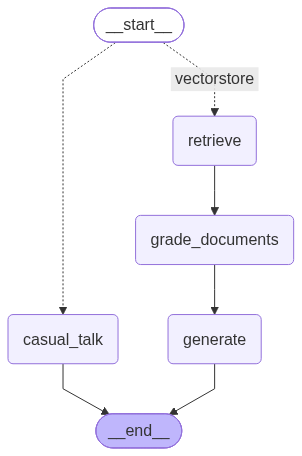

In [47]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    #  실패 시 통과
    pass

### 멀티에이전트 테스트

In [48]:
inputs = {
    "question": "서울시 자율주행 계획"
}

app.invoke(inputs) # workflow를 실행합니다.

------ROUTE------
---Routing to vectorstore---
------RETRIEVE------
------GRADE------
------GENERATE------


{'question': '서울시 자율주행 계획',
 'generation': AIMessage(content='서울시 자율주행 계획은 「2040 서울도시기본계획」에서 미래교통 인프라 구축의 핵심 과제로 제시되어 있습니다.\n\n### 주요 목표\n- **2030년까지** 간선도로급 이상 도로에서 자율주행차가 운행할 수 있도록 도로 인프라와 운영 환경을 단계적으로 조성\n- **2040년까지** 서울 전역에 자율주행 운행 환경 구축\n- 자율주행차의 **수송 분담률 10% 달성**\n\n### 주요 추진 방향\n1. **자율주행 인프라 확충**\n   - 자율주행차 운행에 적합한 도로·통신·운영 인프라를 단계적으로 구축\n   - 교통수단 도입 이후가 아니라 개발 단계부터 도시계획과 연계해 인프라를 지원\n\n2. **기존 교통수단과의 연계**\n   - 자율주행을 기존 대중교통과 분리된 수단이 아니라 다양한 통행수단이 공존하는 포용적 교통체계의 일부로 운영\n   - 주요 거점에 광역형·지역형·근린형 등 위계별 환승체계를 마련\n\n3. **모빌리티 허브 구축**\n   - 도심 및 광역거점에 자율주행, 대중교통 등 미래교통과 기존 교통을 연결하는 거점 조성\n   - 교통 환승뿐 아니라 공공서비스, 물류, 상업 기능을 결합한 복합형 모빌리티 허브를 서울 전역에 도입\n\n4. **3차원 미래교통체계와 연계**\n   - 자율주행차뿐 아니라 도심항공교통(UAM), 3차원 물류체계 등과 연계해 입체적인 교통시스템 구축\n   - 자율주행 기반과 서울형 도심항공교통 인프라를 함께 확충\n\n즉, 서울시의 자율주행 계획은 단순히 자율주행차를 도입하는 데 그치지 않고, **도로 인프라 구축, 대중교통 환승, 모빌리티 허브, 물류 및 UAM을 포함한 도시 전체의 미래교통 체계를 재편하는 장기 계획**이라고 볼 수 있습니다.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'complet

In [49]:
inputs = {
    "question": "잘 지내고 있어?"
}

app.invoke(inputs) # workflow를 실행합니다.

------ROUTE------
---Routing to casual_talk---
------CASUAL TALK------


{'question': '잘 지내고 있어?',
 'generation': AIMessage(content='응, 잘 지내고 있어! 😊 너는 요즘 어때?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 12, 'total_tokens': 31, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EaJW5muK1y9CxOTMAsaDUB09ikzKs', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a14ece-c4ca-7061-b3ba-ec2f0093b8cf-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 12, 'output_tokens': 19, 'total_tokens': 31, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio'

In [50]:
inputs = {
    "question": "서울시의 자율주행 차량 관련 계획은 무엇이 있나요?"
}

for msg, meta in app.stream(inputs, stream_mode='messages'):
    print(msg.content, end='')

------ROUTE------
---Routing to vectorstore---
------RETRIEVE------
------GRADE------
------GENERATE------
서울시는 「2040 서울도시기본계획」에서 자율주행차량을 미래교통 인프라의 핵심으로 보고 다음과 같은 계획을 제시하고 있습니다.

- **단계적 자율주행 도로 인프라 조성**  
  2030년까지 간선도로급 이상 도로에서 자율주행차량이 운행할 수 있는 도로·통신 등 기반 환경을 구축합니다.

- **2040년 서울 전역 운행 환경 구축**  
  2040년까지 서울 전역에 자율주행차량 운행이 가능한 환경을 조성하는 것을 목표로 합니다.

- **자율주행 수송 분담률 10% 달성**  
  자율주행차량의 운행 환경을 확대해 2040년까지 전체 수송에서 자율주행차량이 차지하는 비율을 10%까지 높이는 목표를 제시했습니다.

- **기존 교통수단과의 통합**  
  자율주행 등 신교통수단이 기존 대중교통과 원활하게 연계되도록 주요 거점에 광역형·지역형·근린형 환승체계를 구축할 계획입니다.

- **모빌리티 허브 조성**  
  도심 및 광역거점에 자율주행을 포함한 미래교통과 기존 교통을 연결하는 모빌리티 허브를 서울 전역에 구축합니다. 이 시설은 교통뿐 아니라 공공서비스, 물류, 상업 기능이 결합된 복합 거점으로 계획됩니다.

- **도시계획 및 안전 가이드라인 마련**  
  자율주행차량 등 새로운 교통수단의 도입에 따른 사고와 도시공간 변화를 관리하기 위해, 기존 교통수단과 신규 교통수단이 조화를 이루도록 통합적인 정착 가이드라인과 공간적 대응방안을 마련할 필요성도 제시하고 있습니다.

즉, 서울시의 계획은 단순히 자율주행차량을 도입하는 데 그치지 않고, 도로 인프라·환승체계·모빌리티 허브·도시계획 가이드라인을 함께 구축해 2040년까지 서울 전역에서 자율주행이 가능한 교통체계를 만드는 것입니다.